In [1]:
import pandas as pd
import seaborn as sns

In [2]:
data = pd.read_csv("insurance.csv")
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


<Axes: xlabel='bmi', ylabel='charges'>

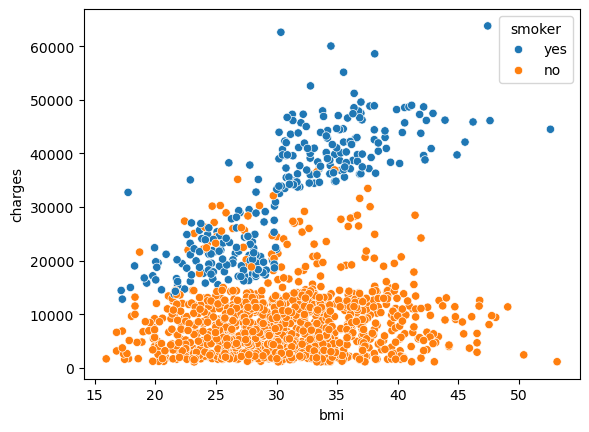

In [7]:
sns.scatterplot(x=data['bmi'], y=data['charges'], hue=data['smoker'])

In [5]:
X = data.drop(columns=["region", "charges"])
y = data["charges"]

# map sex and smoker
X["sex"] = X["sex"].map({"female": 0, "male": 1})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

X.head()

,age,sex,bmi,children,smoker
0,19,0,27.900,0,1
1,18,1,33.770,1,0
2,28,1,33.000,3,0
3,33,1,22.705,0,0
4,32,1,28.880,0,0


In [16]:
# split test and train data using SciKit

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_test.head()

,age,sex,bmi,children,smoker
764,45,0,25.175,2,0
887,36,0,30.020,0,0
890,64,0,26.885,0,1
1293,46,1,25.745,3,0
259,19,1,31.920,0,1


In [19]:
# train
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [24]:
result = model.predict(X_test)

In [25]:
model.intercept_

-12113.451250917084

In [26]:
model.coef_

array([ 2.57068962e+02, -7.95178837e+00,  3.27533514e+02,  4.27254431e+02,
        2.36539033e+04])

model.score(X_train, y_train)

<Axes: xlabel='bmi', ylabel='charges'>

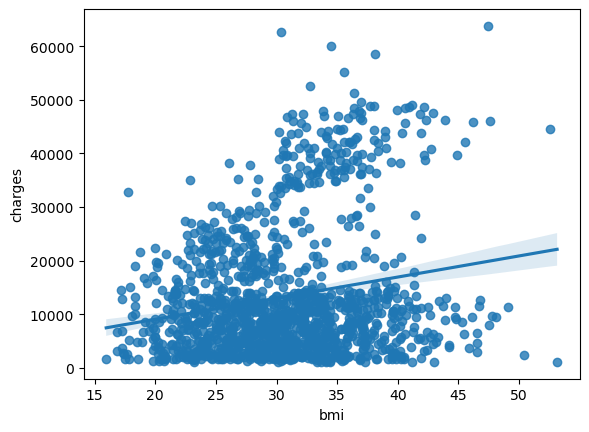

In [27]:
sns.regplot(x="bmi", y="charges", data=data)

In [30]:
# Evaluate
from sklearn.metrics import r2_score

r2_score(y_test, result)

0.7811302113434097